
# Fase 3 — Análisis de Datos

## Notebook 02: Análisis Exploratorio (EDA)

**Proyecto:** Pokémon Team Recommender

### Objetivo

Explorar las distribuciones, relaciones y patrones presentes en
los datos CLEAN de 151 Pokémon de primera generación.

### Preguntas de análisis

1. ¿Cómo se distribuyen las seis estadísticas base?
2. ¿Qué Pokémon presentan mayores valores en cada estadística?
3. ¿Qué relaciones existen entre las estadísticas?
4. ¿Qué tipos aparecen con mayor frecuencia?
5. ¿Cómo se distribuyen las debilidades y resistencias defensivas?
6. ¿Qué características podrían resultar útiles para el clustering?

### Alcance

El análisis es descriptivo y exploratorio.

No se entrenarán modelos ni se aplicará PCA o clustering
durante esta etapa.


In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

def find_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "data" / "clean").is_dir():
            if (path / "ingenieria").is_dir():
                return path

    raise FileNotFoundError(
        "No se encontró la raíz del proyecto."
    )

ROOT = find_root(Path.cwd())
CLEAN = ROOT / "data" / "clean"

pokemon = pd.read_csv(CLEAN / "pokemon.csv")
stats = pd.read_csv(CLEAN / "pokemon_stats.csv")
pokemon_types = pd.read_csv(CLEAN / "pokemon_types.csv")
types = pd.read_csv(CLEAN / "types.csv")
defensive = pd.read_csv(
    CLEAN / "pokemon_defensive_profile.csv"
)

print("Pokémon:", len(pokemon))
print("Estadísticas:", len(stats))
print("Relaciones de tipos:", len(pokemon_types))
print("Tipos:", len(types))
print("Perfiles defensivos:", len(defensive))


Pokémon: 151
Estadísticas: 906
Relaciones de tipos: 218
Tipos: 18
Perfiles defensivos: 2718


In [2]:

# Estadísticas base por categoría

summary_stats = (
    stats.groupby("stat_name")["base_stat"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(summary_stats)


,count,mean,median,std,min,max
stat_name,,,,,,
attack,151,72.91,70.0,26.76,5,134
defense,151,68.23,65.0,26.92,5,180
hp,151,64.21,60.0,28.59,10,250
special-attack,151,67.14,65.0,28.53,15,154
special-defense,151,66.09,65.0,24.21,20,125
speed,151,69.07,70.0,27.02,15,150


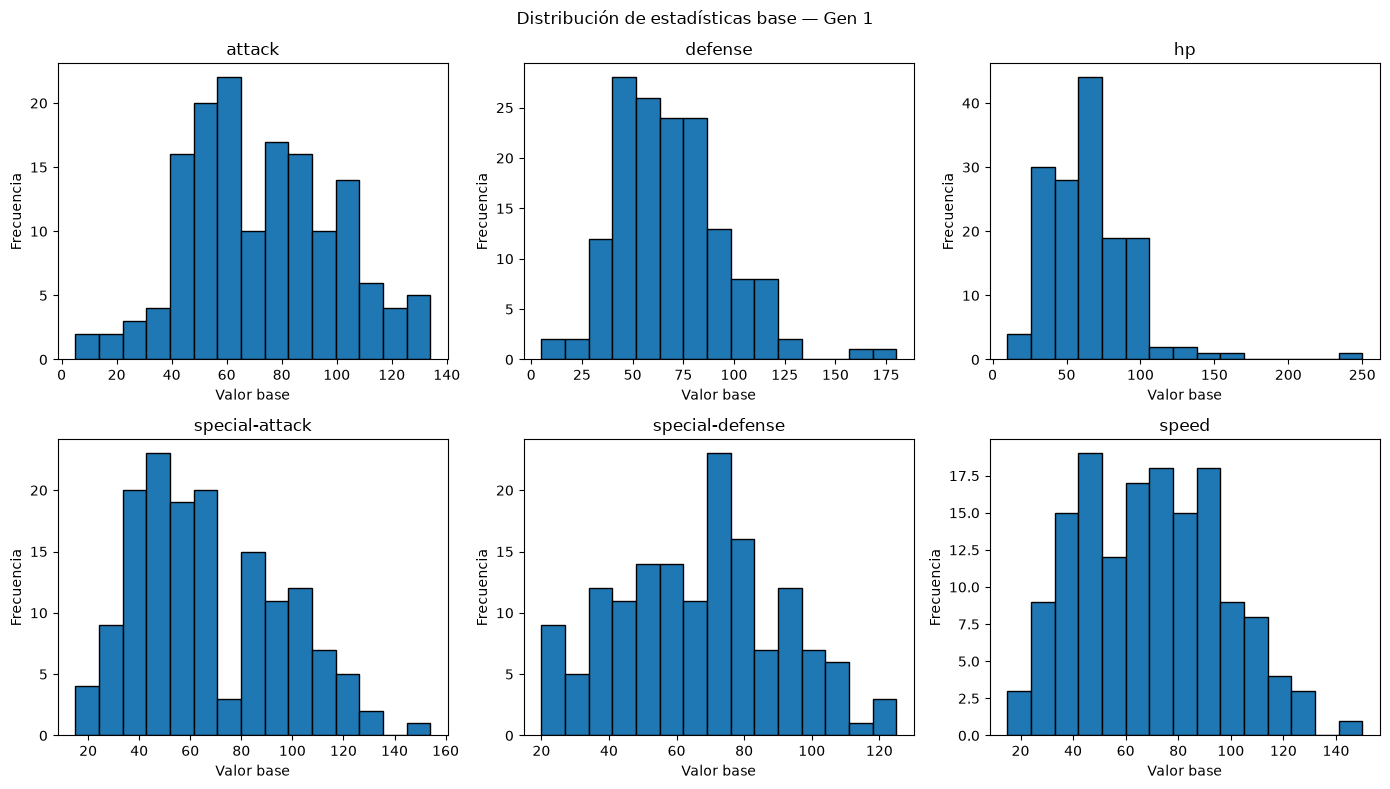

In [3]:

# Distribución de las seis estadísticas base

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

stat_names = sorted(stats["stat_name"].unique())

for ax, stat_name in zip(axes.flat, stat_names):
    values = stats.loc[
        stats["stat_name"] == stat_name,
        "base_stat"
    ]

    ax.hist(values, bins=15, edgecolor="black")
    ax.set_title(stat_name)
    ax.set_xlabel("Valor base")
    ax.set_ylabel("Frecuencia")

plt.suptitle(
    "Distribución de estadísticas base — Gen 1"
)
plt.tight_layout()
plt.show()


=== MATRIZ DE CORRELACIÓN ===


stat_name,attack,defense,hp,special-attack,special-defense,speed
stat_name,,,,,,
attack,1.000,0.483,0.297,0.140,0.370,0.201
defense,0.483,1.000,0.120,0.188,0.142,-0.052
hp,0.297,0.120,1.000,0.237,0.494,-0.041
special-attack,0.140,0.188,0.237,1.000,0.528,0.408
special-defense,0.370,0.142,0.494,0.528,1.000,0.388
speed,0.201,-0.052,-0.041,0.408,0.388,1.000


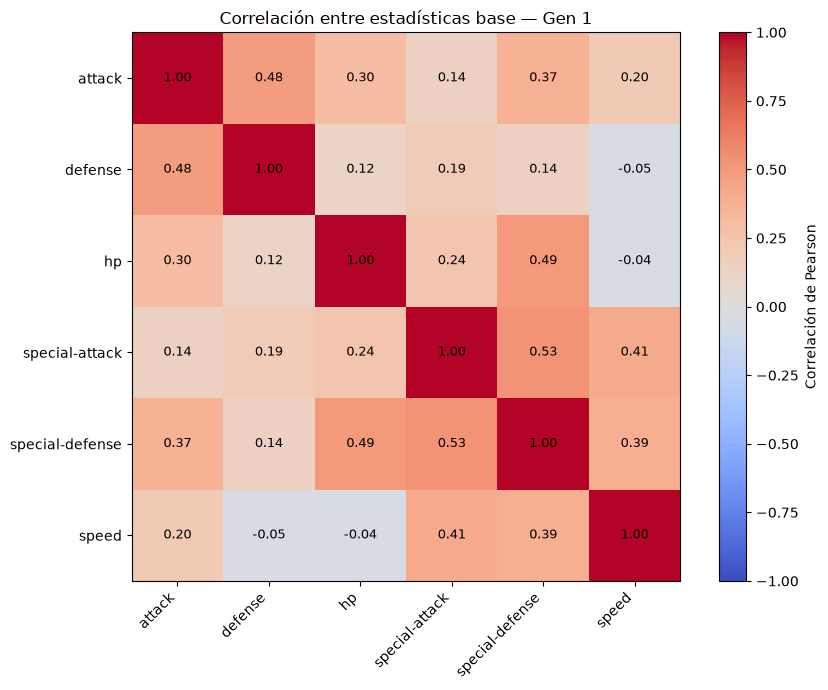

In [4]:

# Matriz de correlación entre estadísticas base

stats_wide = stats.pivot(
    index="pokemon_id",
    columns="stat_name",
    values="base_stat"
)

# Verificar que cada Pokémon tenga sus seis estadísticas
assert stats_wide.shape == (151, 6)
assert not stats_wide.isna().any().any()

correlation = stats_wide.corr(method="pearson")

print("=== MATRIZ DE CORRELACIÓN ===")
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.index)))

ax.set_xticklabels(
    correlation.columns,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(correlation.index)

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(image, ax=ax, label="Correlación de Pearson")
plt.title("Correlación entre estadísticas base — Gen 1")
plt.tight_layout()
plt.show()


=== FRECUENCIA DE TIPOS ===


,type_name,cantidad_pokemon
0,poison,33
1,water,32
2,normal,22
3,flying,19
4,ground,14
5,psychic,14
6,grass,14
7,bug,12
8,fire,12
9,rock,11


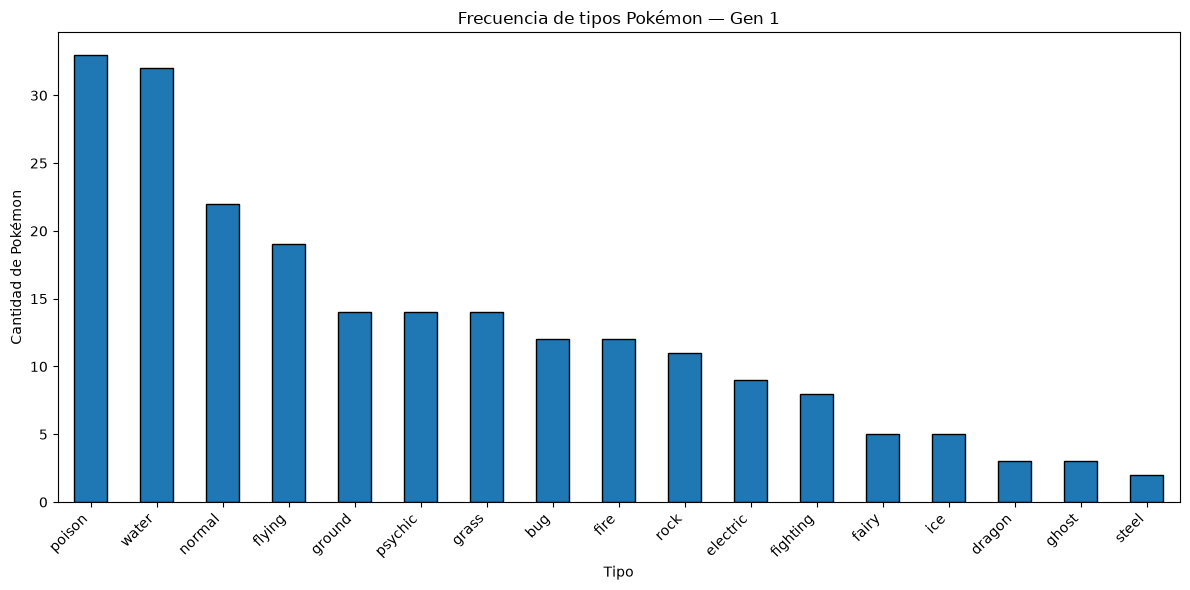

In [5]:

# Análisis de frecuencia de tipos Pokémon

type_frequency = (
    pokemon_types
    .groupby("type_name")["pokemon_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("=== FRECUENCIA DE TIPOS ===")
display(
    type_frequency.reset_index(
        name="cantidad_pokemon"
    )
)

plt.figure(figsize=(12, 6))

type_frequency.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Frecuencia de tipos Pokémon — Gen 1")
plt.xlabel("Tipo")
plt.ylabel("Cantidad de Pokémon")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


=== CANTIDAD DE TIPOS POR POKÉMON ===


,numero_tipos,cantidad_pokemon
0,1,84
1,2,67


Total de Pokémon: 151
Pokémon sin tipos: 0


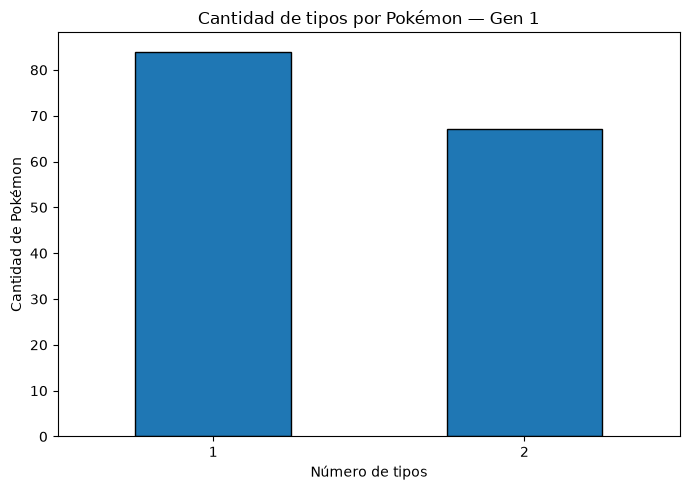

In [6]:

# Análisis de cantidad de tipos por Pokémon

types_per_pokemon = (
    pokemon_types.groupby("pokemon_id")["type_id"]
    .nunique()
    .reindex(pokemon["pokemon_id"], fill_value=0)
)

type_count = (
    types_per_pokemon
    .value_counts()
    .sort_index()
)

print("=== CANTIDAD DE TIPOS POR POKÉMON ===")
display(
    type_count.reset_index(
        name="cantidad_pokemon"
    ).rename(
        columns={"type_id": "numero_tipos"}
    )
)

print("Total de Pokémon:", len(types_per_pokemon))
print(
    "Pokémon sin tipos:",
    int((types_per_pokemon == 0).sum())
)

plt.figure(figsize=(7, 5))

type_count.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Cantidad de tipos por Pokémon — Gen 1")
plt.xlabel("Número de tipos")
plt.ylabel("Cantidad de Pokémon")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [7]:

print("=== COLUMNAS DEL PERFIL DEFENSIVO ===")
print(defensive.columns.tolist())

print("\n=== PRIMEROS REGISTROS ===")
display(defensive.head())

print("\n=== MULTIPLICADORES DISPONIBLES ===")
for column in defensive.columns:
    if "multiplier" in column or "multiplicador" in column:
        print(column)
        print(defensive[column].value_counts().sort_index())


=== COLUMNAS DEL PERFIL DEFENSIVO ===
['pokemon_id', 'pokemon_name', 'attacking_type_id', 'attacking_type', 'defensive_multiplier', 'ruleset']

=== PRIMEROS REGISTROS ===


,pokemon_id,pokemon_name,attacking_type_id,attacking_type,defensive_multiplier,ruleset
0,1,bulbasaur,1,normal,1.0,pokeapi_current
1,1,bulbasaur,2,fighting,0.5,pokeapi_current
2,1,bulbasaur,3,flying,2.0,pokeapi_current
3,1,bulbasaur,4,poison,1.0,pokeapi_current
4,1,bulbasaur,5,ground,1.0,pokeapi_current



=== MULTIPLICADORES DISPONIBLES ===
defensive_multiplier
defensive_multiplier
0.00      68
0.25      64
0.50     517
1.00    1605
2.00     433
4.00      31
Name: count, dtype: int64


In [10]:

# Resumen defensivo por Pokémon

defensive_summary = (
    defensive.groupby("pokemon_id")["defensive_multiplier"]
    .agg(
        inmunidades=lambda x: (x == 0).sum(),
        resistencias_dobles=lambda x: (x == 0.25).sum(),
        resistencias=lambda x: (x == 0.5).sum(),
        neutrales=lambda x: (x == 1).sum(),
        debilidades=lambda x: (x == 2).sum(),
        debilidades_dobles=lambda x: (x == 4).sum(),
    )
    .reset_index()
)

defensive_summary = defensive_summary.merge(
    pokemon[["pokemon_id", "pokemon_name"]],
    on="pokemon_id",
    how="left",
    validate="one_to_one"
)

defensive_summary["total_resistencias"] = (
    defensive_summary["resistencias_dobles"]
    + defensive_summary["resistencias"]
)

defensive_summary["total_debilidades"] = (
    defensive_summary["debilidades"]
    + defensive_summary["debilidades_dobles"]
)

# Cada Pokémon debe tener 18 relaciones defensivas.
count_columns = [
    "inmunidades",
    "resistencias_dobles",
    "resistencias",
    "neutrales",
    "debilidades",
    "debilidades_dobles",
]

assert defensive_summary[count_columns].sum(axis=1).eq(18).all()
assert len(defensive_summary) == 151
assert defensive_summary["pokemon_name"].notna().all()

print("=== RESUMEN DEFENSIVO POR POKÉMON ===")

display(
    defensive_summary[
        [
            "pokemon_name",
            "inmunidades",
            "total_resistencias",
            "total_debilidades",
            "debilidades_dobles",
        ]
    ].head(15)
)

print("\n=== ESTADÍSTICAS GENERALES ===")

display(
    defensive_summary[
        [
            "inmunidades",
            "total_resistencias",
            "total_debilidades",
            "debilidades_dobles",
        ]
    ].describe().round(2)
)


=== RESUMEN DEFENSIVO POR POKÉMON ===


,pokemon_name,inmunidades,total_resistencias,total_debilidades,debilidades_dobles
0,bulbasaur,0,5,4,0
1,ivysaur,0,5,4,0
2,venusaur,0,5,4,0
3,charmander,0,6,3,0
4,charmeleon,0,6,3,0
5,charizard,1,6,3,1
6,squirtle,0,4,2,0
7,wartortle,0,4,2,0
8,blastoise,0,4,2,0
9,caterpie,0,3,3,0



=== ESTADÍSTICAS GENERALES ===


,inmunidades,total_resistencias,total_debilidades,debilidades_dobles
count,151.00,151.00,151.00,151.00
mean,0.45,3.85,3.07,0.21
std,0.65,1.96,1.37,0.52
min,0.00,0.00,1.00,0.00
25%,0.00,2.00,2.00,0.00
50%,0.00,4.00,3.00,0.00
75%,1.00,5.00,4.00,0.00
max,2.00,11.00,7.00,2.00


In [11]:

# Ranking de perfiles defensivos

print("=== TOP 10: MÁS RESISTENCIAS ===")

display(
    defensive_summary.sort_values(
        ["total_resistencias", "inmunidades"],
        ascending=False
    )[
        [
            "pokemon_name",
            "inmunidades",
            "total_resistencias",
            "total_debilidades",
            "debilidades_dobles"
        ]
    ].head(10)
)

print("\n=== TOP 10: MÁS DEBILIDADES ===")

display(
    defensive_summary.sort_values(
        ["total_debilidades", "debilidades_dobles"],
        ascending=False
    )[
        [
            "pokemon_name",
            "inmunidades",
            "total_resistencias",
            "total_debilidades",
            "debilidades_dobles"
        ]
    ].head(10)
)

print("\n=== TOP 10: MÁS INMUNIDADES ===")

display(
    defensive_summary.sort_values(
        ["inmunidades", "total_resistencias"],
        ascending=False
    )[
        [
            "pokemon_name",
            "inmunidades",
            "total_resistencias",
            "total_debilidades",
            "debilidades_dobles"
        ]
    ].head(10)
)


=== TOP 10: MÁS RESISTENCIAS ===


,pokemon_name,inmunidades,total_resistencias,total_debilidades,debilidades_dobles
80,magnemite,1,11,3,1
81,magneton,1,11,3,1
71,tentacool,0,8,3,0
72,tentacruel,0,8,3,0
61,poliwrath,0,7,5,0
5,charizard,1,6,3,1
145,moltres,1,6,3,1
3,charmander,0,6,3,0
4,charmeleon,0,6,3,0
36,vulpix,0,6,3,0



=== TOP 10: MÁS DEBILIDADES ===


,pokemon_name,inmunidades,total_resistencias,total_debilidades,debilidades_dobles
101,exeggcute,0,6,7,1
102,exeggutor,0,6,7,1
45,paras,0,5,6,2
46,parasect,0,5,6,2
73,geodude,1,5,6,2
74,graveler,1,5,6,2
75,golem,1,5,6,2
94,onix,1,5,6,2
110,rhyhorn,1,5,6,2
111,rhydon,1,5,6,2



=== TOP 10: MÁS INMUNIDADES ===


,pokemon_name,inmunidades,total_resistencias,total_debilidades,debilidades_dobles
91,gastly,2,4,4,0
92,haunter,2,4,4,0
93,gengar,2,4,4,0
15,pidgey,2,2,3,0
16,pidgeotto,2,2,3,0
17,pidgeot,2,2,3,0
20,spearow,2,2,3,0
21,fearow,2,2,3,0
38,jigglypuff,2,2,2,0
39,wigglytuff,2,2,2,0


In [12]:

# Análisis descriptivo de complementariedad defensiva

team = ["magnemite", "charizard", "blastoise"]

team_defensive = defensive[
    defensive["pokemon_name"].isin(team)
].copy()

team_matrix = team_defensive.pivot(
    index="attacking_type",
    columns="pokemon_name",
    values="defensive_multiplier"
)

assert team_matrix.shape == (18, 3)
assert not team_matrix.isna().any().any()

# Mejor respuesta defensiva disponible dentro del equipo
team_matrix["mejor_multiplicador"] = (
    team_matrix[team].min(axis=1)
)

# Cantidad de integrantes vulnerables al tipo atacante
team_matrix["integrantes_debiles"] = (
    team_matrix[team] > 1
).sum(axis=1)

# Tipos frente a los que todo el equipo es vulnerable
team_matrix["debilidad_compartida"] = (
    team_matrix["integrantes_debiles"] == 3
)

print("=== PERFIL DEFENSIVO DEL EQUIPO ===")
display(team_matrix)

print("\n=== RESUMEN ===")
print(
    "Tipos con al menos una resistencia o inmunidad:",
    int((team_matrix["mejor_multiplicador"] < 1).sum())
)
print(
    "Tipos con debilidad compartida por los 3:",
    int(team_matrix["debilidad_compartida"].sum())
)


=== PERFIL DEFENSIVO DEL EQUIPO ===


pokemon_name,blastoise,charizard,magnemite,mejor_multiplicador,integrantes_debiles,debilidad_compartida
attacking_type,,,,,,
bug,1.0,0.25,0.50,0.25,0,False
dark,1.0,1.00,1.00,1.00,0,False
dragon,1.0,1.00,0.50,0.50,0,False
electric,2.0,2.00,0.50,0.50,2,False
fairy,1.0,0.50,0.50,0.50,0,False
fighting,1.0,0.50,2.00,0.50,1,False
fire,0.5,0.50,2.00,0.50,1,False
flying,1.0,1.00,0.25,0.25,0,False
ghost,1.0,1.00,1.00,1.00,0,False



=== RESUMEN ===
Tipos con al menos una resistencia o inmunidad: 16
Tipos con debilidad compartida por los 3: 0


In [13]:

# Resumen de complementariedad defensiva del equipo

covered = team_matrix["mejor_multiplicador"] < 1
neutral_only = team_matrix["mejor_multiplicador"] == 1
uncovered = team_matrix["mejor_multiplicador"] > 1

shared_weakness = team_matrix["debilidad_compartida"]

print("=== COBERTURA DEFENSIVA DEL EQUIPO ===")
print(f"Tipos cubiertos: {covered.sum()}/18")
print(f"Tipos sin resistencia: {neutral_only.sum()}/18")
print(f"Tipos con todos los integrantes débiles: {uncovered.sum()}/18")
print(f"Debilidades compartidas: {shared_weakness.sum()}")

print("\n=== TIPOS SIN RESISTENCIA DISPONIBLE ===")
print(team_matrix.index[neutral_only].tolist())

print("\n=== TIPOS CON RESISTENCIA O INMUNIDAD ===")
print(team_matrix.index[covered].tolist())


=== COBERTURA DEFENSIVA DEL EQUIPO ===
Tipos cubiertos: 16/18
Tipos sin resistencia: 2/18
Tipos con todos los integrantes débiles: 0/18
Debilidades compartidas: 0

=== TIPOS SIN RESISTENCIA DISPONIBLE ===
['dark', 'ghost']

=== TIPOS CON RESISTENCIA O INMUNIDAD ===
['bug', 'dragon', 'electric', 'fairy', 'fighting', 'fire', 'flying', 'grass', 'ground', 'ice', 'normal', 'poison', 'psychic', 'rock', 'steel', 'water']
